**Examples: SKLearn, Linear Regression**

Imports, read data file, etc.

In [2]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn.linear_model


# Set the option to display all columns
pd.set_option('display.max_columns', None)
# Set the option to display more width (scroll to the right)
pd.set_option('display.width', 1000)

# import data file:
df_house_data = pd.read_csv("https://raw.githubusercontent.com/bu-cds-omds/dx602-examples/refs/heads/main/data/kc_house_data.csv", index_col="id")

print(f"Read {len(df_house_data)} recods.")
print(df_house_data.columns)




Read 21613 recods.
Index(['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15'], dtype='str')


Explore the data a bit

descriptive statistics: 
              price      bedrooms     bathrooms   sqft_living
count  2.110000e+04  21100.000000  21100.000000  21100.000000
mean   5.166571e+05      3.316777      2.084147   2035.364123
std    2.857103e+05      0.829645      0.733342    849.899038
min    7.500000e+04      0.000000      0.000000    290.000000
25%    3.200000e+05      3.000000      1.500000   1410.000000
50%    4.480000e+05      3.000000      2.250000   1890.000000
75%    6.305000e+05      4.000000      2.500000   2500.000000
max    2.000000e+06      5.000000      6.000000   7730.000000


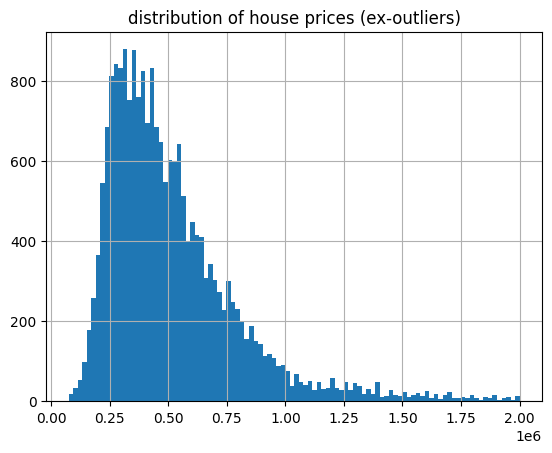

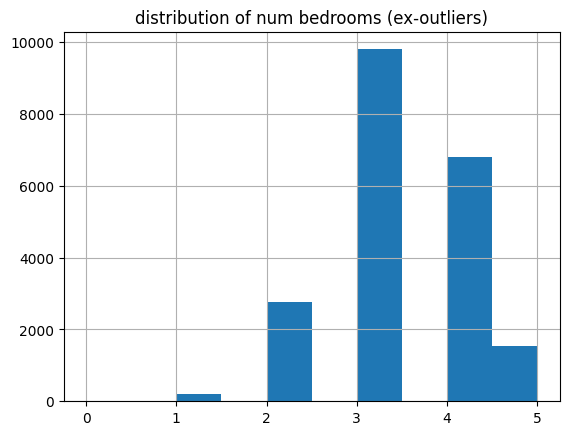

In [20]:
#print(df_house_data[['price', 'bedrooms', 'bathrooms', 'sqft_living']])

print("descriptive statistics: ")
# print(df_house_data[['price', 'bedrooms', 'bathrooms', 'sqft_living']].describe())

# try a histogram
# df_house_data['price'].hist(bins=100)
# try log of price
# s_price = np.log(df_house_data['price'])
# plt.hist(s_price)
# plt.title("distribution of price")


# try: let's exclude the mega houses from this data set:
# df_tmp = df_house_data.query('price <= 2000000')
# df_tmp = df_house_data.query('bedrooms <= 5')
df_tmp = df_house_data.query('price <= 2000000').query('bedrooms <= 5')
print(df_tmp[['price', 'bedrooms', 'bathrooms', 'sqft_living']].describe())
df_tmp['price'].hist(bins=100)
plt.title("distribution of house prices (ex-outliers)")
plt.show()

df_tmp['bedrooms'].hist()
plt.title("distribution of num bedrooms (ex-outliers)")
plt.show()

Scatter plots

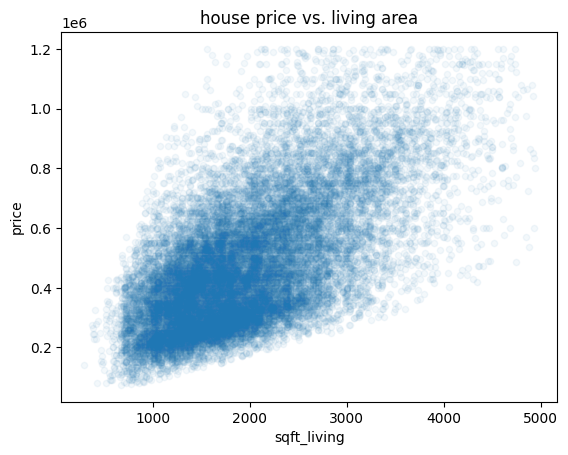

bedrooms
3     9824
4     6882
2     2760
5     1601
6      272
1      199
7       38
0       13
8       13
9        6
10       3
11       1
33       1
Name: count, dtype: int64


In [29]:
# let's look at the size (sqft_living) vs price
# df_house_data.plot.scatter('sqft_living', 'price')

# exclude some outliers:
df_tmp = df_house_data.query('price <= 1200000').query('sqft_living <= 5000')
df_tmp.plot.scatter('sqft_living', 'price', alpha=0.05)
plt.title("house price vs. living area")
plt.show()

print(df_house_data['bedrooms'].value_counts())

Add: coloring by category (number of bedrooms)

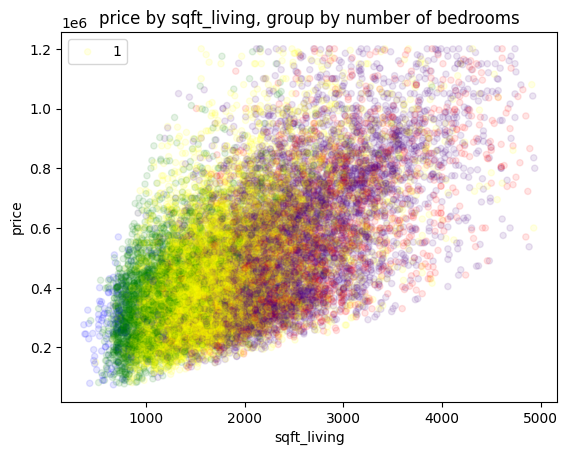

In [ ]:
# exclude some outliers:
df_tmp = df_house_data.query('price <= 1200000')
df_tmp = df_tmp.query('sqft_living <= 5000')
df_tmp = df_tmp.query('1 <= bedrooms <= 5')
# df_tmp.plot.scatter('sqft_living', 'price', alpha=0.05)
# plt.title("house price vs. living area")
# plt.show()

#print(df_house_data['bedrooms'].value_counts())
# create a coloring scheme
colors = {1: 'blue', 2: 'green', 3:'yellow', 4:'indigo', 5: 'red'}
# map the colors to the number of bedrooms
df_tmp['color'] = df_tmp['bedrooms'].map(colors)
# print(df_tmp[['bedrooms', 'color']]) # spot check the data

# show the scatterplot with colors for count of bedrooms
df_tmp.plot.scatter('sqft_living', 'price', c='color', alpha=0.1)
plt.title("price by sqft_living, group by number of bedrooms")
plt.show()


**Linear Regression:**

try to fit an equation to explain an outcome variable (y) as a function
of some other variable(s)

- OLS (ordinary least squares) attempts minimize the prediction error


model score: 0.39552456209106424


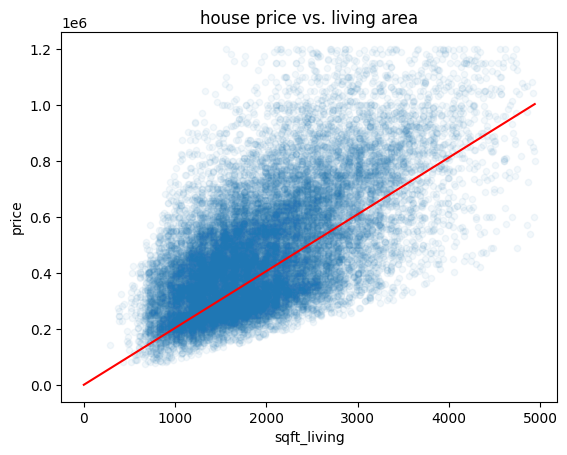

model score: 0.09221668496437885


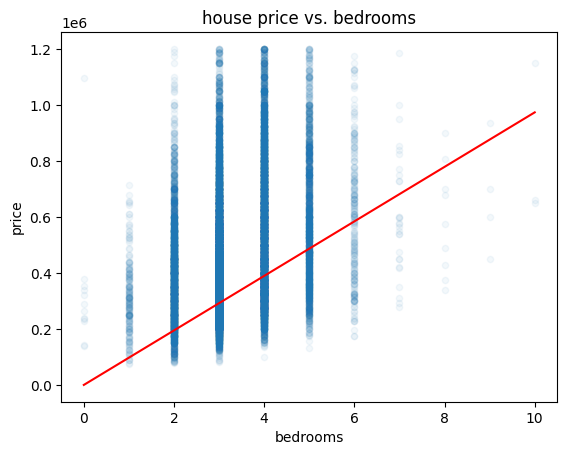

In [ ]:

# exclude some outliers:
df_tmp = df_house_data.query('price <= 1200000').query('sqft_living <= 5000')
df_tmp = df_tmp.query('bedrooms <= 10')

### USE LIVING SPACE (sqft_living) ###
df_tmp.plot.scatter('sqft_living', 'price', alpha=0.05)
plt.title("house price vs. living area")
# plt.show() # shows the picture, can't add any more

# specify the target (outcome) variable
target = df_tmp['price']
# specify the feature column(s) (explantory) variable(s)
features = df_tmp[['sqft_living']] # a list containing one column
# "build" a regression model
model = sklearn.linear_model.LinearRegression()
# fit the best equation for this data
model.fit(features, target) # (x values, y value)
print("model score:", model.score(features, target))

# ask the model to predict the price for each value of sqft_living
model_predictions = model.predict(features)
# add a line to the scatter plot from this model:
max_value_price = model_predictions.max()
max_value_sqft_living = df_tmp['sqft_living'].max()
plt.plot([0, max_value_sqft_living], [0, max_value_price], color="red")
plt.show() # shows the picture, can't add any more


### USE LIVING SPACE (bedrooms) ###
df_tmp.plot.scatter('bedrooms', 'price', alpha=0.05)
plt.title("house price vs. bedrooms")
# plt.show() # shows the picture, can't add any more

# specify the target (outcome) variable
target = df_tmp['price']
# specify the feature column(s) (explantory) variable(s)
features = df_tmp[['bedrooms']] # a list containing one column
# "build" a regression model
model = sklearn.linear_model.LinearRegression()
# fit the best equation for this data
model.fit(features, target) # (x values, y value)
print("model score:", model.score(features, target))

# ask the model to predict the price for each value of bedrooms
model_predictions = model.predict(features)
# add a line to the scatter plot from this model:
max_value_price = model_predictions.max()
max_value_bedrooms = df_tmp['bedrooms'].max()
plt.plot([0, max_value_bedrooms], [0, max_value_price], color="red")
plt.show() # shows the picture, can't add any more



Multiple regression

In [71]:

# exclude some outliers:
df_tmp = df_house_data.query('price <= 1200000').query('sqft_living <= 5000')
df_tmp = df_tmp.query('bedrooms <= 10')

# specify the target (outcome) variable
target = df_tmp['price']
# specify the feature column(s) (explantory) variable(s)
columns = ['sqft_living', 'bedrooms', 'bathrooms', 'sqft_lot']
features = df_tmp[columns] 
# "build" a regression model
model = sklearn.linear_model.LinearRegression()
# fit the best equation for this data
model.fit(features, target) # (x values, y value)
print("outcome: price" )
print("features:", columns)
print("model score:", model.score(features, target))


## add: correlation matrix
numeric_cols = ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated',]
correl_matrix = df_tmp[numeric_cols].corr()
print(correl_matrix)

# bonus: heatmap with seaborn
import seaborn as sns
# 2. Plot the heatmap with cell annotations and axis labels
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,  # Display correlation values inside cells
    fmt=".2f",  # Round values to 2 decimal places
    cmap="coolwarm",  # Diverging color palette (blue to red)
    vmin=-1,
    vmax=1,  # Anchor color scale from -1 to 1
    square=True,  # Keep cells square
)

plt.title("Correlation Matrix")
plt.xticks(rotation=45, ha="right")  # Rotate x-labels so they don't overlap
plt.tight_layout()
plt.show()


outcome: price
features: ['sqft_living', 'bedrooms', 'bathrooms', 'sqft_lot']
model score: 0.4049710421009427
                  price  bedrooms  bathrooms  sqft_living  sqft_lot    floors  waterfront      view  condition     grade  sqft_above  sqft_basement  yr_built  yr_renovated
price          1.000000  0.303672   0.457145     0.628907  0.089725  0.274004    0.069292  0.248501   0.037482  0.637522    0.533847       0.235932  0.059043      0.091003
bedrooms       0.303672  1.000000   0.507062     0.601601  0.023399  0.159801   -0.034900  0.038126   0.024002  0.331899    0.475685       0.288011  0.165539      0.003201
bathrooms      0.457145  0.507062   1.000000     0.715986  0.061317  0.502296   -0.002706  0.095353  -0.135775  0.613671    0.635881       0.218506  0.542627      0.028078
sqft_living    0.628907  0.601601   0.715986     1.000000  0.153224  0.344369    0.002949  0.167375  -0.071703  0.709602    0.852965       0.367812  0.354715      0.024056
sqft_lot       0.089725  0.023

ModuleNotFoundError: No module named 'seaborn'